# 07 · What fair exposure costs (E2)

**Experiment E2 of the project plan.** The proposed recommender (notebook 06) re-ranks each member's five suggestions with four dials:
a quota *q* and a cap *c* for fair exposure (rule R4), a topic cap *n* and a variety weight λ for diversity (rule R5).
Each dial serves a value, and each can cost accuracy. This notebook measures how much, and recommends a setting for each dial.

What it does:

1. tries **every combination** of the dial values listed in the interim report (plus q = 60% and five values of λ): 180 settings;
2. **chooses** the dials on the practice quiz only, with a rule fixed before the test is looked at: accuracy is a budget, not the goal;
3. **reports** every setting on the test: the trade-off curve, the key figure of the report (`figures/e2_tradeoff.png`), with the best settings
   (the *Pareto front*), today's BOING, the hybrid without re-ranking and the recommended setting marked;
4. explains, dial by dial, what each one costs in accuracy, what it gives in exposure or variety, and which value it serves.

Run notebooks 01, 02 and 06 first (06 writes the E1 table this notebook compares with). The code shared by all notebooks is in `boingrec.py`, in this folder.

## 0 · Settings and data

In [1]:
# Colab only: upload sim_v1.zip and sim_v1_split.zip (from notebooks 01 and 02) and boingrec.py (from the notebooks folder),
# all three at once. Locally this cell does nothing.
import sys, zipfile
from pathlib import Path
if 'google.colab' in sys.modules and not Path('boingrec.py').exists():
    from google.colab import files
    for fname in files.upload():
        if fname.endswith('.zip'):
            with zipfile.ZipFile(fname) as z:
                z.extractall('data')

In [2]:
import hashlib
import inspect
import itertools
import json
import math
from dataclasses import asdict, replace
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import boingrec as br

SEED, K = br.SEED, br.K           # 0 and 5, the same in every notebook
br.use_style()
cfg = br.Config()                 # the proposed design of notebook 06: everything except the four dials stays as it is

# The dial values to try: the interim report's (Table 3), plus q = 60% and the values of lambda notebook 06 tried
QS = [0.0, 0.2, 0.4, 0.6]         # R4 quota: at least q of each list goes to new or small groups (1, 2 or 3 slots of 5)
CS = [0.05, 0.1, None]            # R4 global cap: no group gets more than c of all slots (None = no cap)
NS = [2, 3, 5]                    # R5 topic cap: at most n groups of one public topic per list (5 = no cap)
LAMS = [1.0, 0.9, 0.8, 0.7, 0.5]  # R5 variety (MMR): 1 = relevance only; lower = less similar groups in a list
BUDGET = 0.05                     # the most NDCG@5 we accept to lose, as a share of the hybrid's (section 4)

vis = br.load_visible()           # what a recommender may read: no test file, no hidden column
ans = br.load_answers()           # the answer key: only the scoring code reads it
tested = sorted(ans.test.user_id.unique())
fit, val = br.val_split(vis)      # the practice quiz of notebooks 04 to 06
val_users = sorted(val.user_id.unique())
print(f'{len(QS) * len(CS) * len(NS) * len(LAMS)} settings to try. Practice quiz: {len(val_users)} users; test: {len(tested)} users.')
pd.Series(asdict(cfg), dtype=object).to_frame('notebook 06').T

180 settings to try. Practice quiz: 1090 users; test: 1406 users.


,alpha,beta,gamma,delta,k,topic_weight,personal,off_new_w,q,c,...,burst_w,young_days,eps,m,size_share,noise_seed,seed,small_from,r9_scope,act_eps
notebook 06,0.4,0.1,0.3,0.2,10,0.0,True,0.5,0.2,0.1,...,1.0,30,None,None,0.25,None,0,counted,joins,None


## 1 · The four dials

| Dial | Rule | What it does | Values tried | Value it serves |
|---|---|---|---|---|
| **q**, the quota | R4 | At least ⌈q × 5⌉ of the 5 suggestions are new groups (created in the last 30 days) or small ones (fewer than 10 members): the most relevant of them | 0%, 20% (1 slot), 40% (2), 60% (3) | Equity and inclusion: a new group cannot gain members if nobody sees it |
| **c**, the global cap | R4 | No group gets more than c of all the slots shown to all members together | 5%, 10%, no cap | Equity: no group takes everyone's attention |
| **n**, the topic cap | R5 | At most n groups of one public topic in a list (topics found from the groups' descriptions, notebook 06) | 2, 3, 5 (= no cap) | Diversity and autonomy: lists that are not all one subject |
| **λ**, the variety weight | R5 | Each next slot takes the group with the best λ · relevance − (1 − λ) · similarity to the groups already picked (*MMR*) | 1 (relevance only), 0.9, 0.8, 0.7, 0.5 | Diversity: groups unlike each other |

Every combination: 4 × 3 × 3 × 5 = **180 settings**. The hybrid's weights, the AI model and the reasons stay exactly as chosen in notebooks 05 and 06.
The un-re-ranked hybrid is one of the settings: q = 0, no cap, n = 5, λ = 1.

## 2 · A fast way to try 180 settings

`br.recommend()` does three things: it scores every group for every member, re-ranks with the dials, and writes the reasons. The dials only act in the
second step. So for each split we run `recommend()` **once**, keep exactly what it hands to the re-ranker (`br.rerank`), and then re-run only the
re-ranker for each setting. The checks below show that this gives exactly the same lists as `recommend()`.

For each setting we keep the usual numbers (those of `br.evaluate`: hit rate, precision, recall, NDCG@5, newcomer share, Gini, coverage, largest share,
topics per list) and four more: *diversity* (1 − the average description similarity of the pairs of groups in a list, as `br.list_diversity`),
*clusters_per_list* (public topics per list), *quota_slots* (the share of slots the quota changed) and *times_relaxed* (how often a rule had to give way).
We also keep each user's NDCG@5, to compare two settings on the same users. To score 360 settings quickly, the numbers are computed with a few lines of
numpy instead of `br.evaluate()`; a check shows they are exactly the same.

In [3]:
DIALS = ['q', 'c', 'n', 'lam']
GRID = list(itertools.product(QS, CS, NS, LAMS))     # every setting (q, c, n, lambda)


def setting(q, c, n, lam):
    # A readable name for one setting, used as its key everywhere
    return f'q={q:.0%} c={"none" if c is None or c != c else f"{c:.0%}"} n={n} lam={lam}'


def dials_of(config):
    return {d: getattr(config, d) for d in DIALS}


def with_c(grid, c):
    # The rows of a results table whose cap is c (None = no cap)
    return grid[grid.c.isna()] if c is None else grid[grid.c == c]


def reranker_inputs(users, v, stats, config):
    # Run recommend() once and keep exactly what it hands to the re-ranker (none of it depends on q, c, n or lambda)
    kept = {}
    real_rerank = br.rerank

    def keep(*args, **kwargs):                       # a stand-in that writes down its inputs, then re-ranks as usual
        kept.update(inspect.signature(real_rerank).bind(*args, **kwargs).arguments)
        return real_rerank(*args, **kwargs)

    br.rerank = keep
    try:
        recs = br.recommend(users, v, config, stats)
    finally:
        br.rerank = real_rerank                      # always put the real re-ranker back
    kept.update(users=np.unique(users), gids=br.group_ids(v), recs=recs, base=config,
                codes=np.unique(np.asarray(kept['cluster']), return_inverse=True)[1])   # public topics as 0, 1, 2...
    return kept


def rerank_with(inp, **dials):
    # Re-run only the re-ranker, with other dial values. Returns (picks, forced, relaxed), as br.rerank does
    return br.rerank(inp['relevance'], inp['allowed'], inp['sim'], inp['newcomer'], inp['cluster'],
                     replace(inp['base'], **dials), inp['order'])


def as_lists(inp, picks):
    # The re-ranker's column numbers -> {user_id: [group_id, ...]}, the format br.evaluate() takes
    return {int(u): [int(inp['gids'][j]) for j in row if j >= 0] for u, row in zip(inp['users'], picks)}


def same_as_recommend(inp, recs, dials):
    # True if re-running only the re-ranker gives exactly recommend()'s lists and quota slots
    picks, forced, _ = rerank_with(inp, **dials)
    forced_fast = {(int(u), int(r) + 1) for u, row in zip(inp['users'], forced) for r in np.flatnonzero(row)}
    forced_recs = {(int(u), int(r)) for u, r in zip(recs.user_id[recs.forced], recs['rank'][recs.forced])}
    return as_lists(inp, picks) == br.lists_from(recs) and forced_fast == forced_recs


DISCOUNT = 1 / np.log2(np.arange(2, K + 2))          # what a right answer is worth at positions 1 to 5 (NDCG)
PAIRS = np.triu_indices(K, k=1)                       # the 10 pairs of positions in a list of 5


def answer_key(inp, truth, v):
    # What the scoring needs, once per split. It reads the answer key (hidden memberships and topics): scoring only
    users, gids = inp['users'], inp['gids']
    assert set(truth.user_id) == set(users) and truth.group_id.isin(gids).all(), 'serve exactly the users with hidden groups'
    hidden = np.zeros((len(users), len(gids)), dtype=bool)
    hidden[np.searchsorted(users, truth.user_id), np.searchsorted(gids, truth.group_id)] = True
    return {'hidden': hidden, 'n_hidden': hidden.sum(axis=1), 'on_discover': np.isin(gids, br.discover_groups(v.groups)),
            'newcomer': np.isin(gids, sorted(br.newcomer_groups(v))),     # new or small, exactly as br.evaluate counts them
            'topic': pd.factorize(ans.group_topic.reindex(gids))[0]}


def measure(inp, key, picks, forced, relaxed):
    # Every number for one setting, and each user's NDCG@5 (as br.evaluate and br.list_diversity: checked below)
    users = np.arange(len(picks))[:, None]
    hits = key['hidden'][users, picks]                                 # users x 5: True where a suggestion is a hidden group
    found = hits.sum(axis=1)
    ndcg = (hits * DISCOUNT).sum(axis=1) / np.cumsum(DISCOUNT)[np.minimum(key['n_hidden'], K) - 1]
    counts = np.bincount(picks.ravel(), minlength=len(inp['gids']))
    shown = counts[key['on_discover']]                                 # every Discover group, 0 if never shown
    topics = np.sort(key['topic'][picks], axis=1)
    pair_sim = inp['sim'][picks[:, :, None], picks[:, None, :]][:, PAIRS[0], PAIRS[1]]
    codes = inp['codes'][picks]
    per_cluster = (codes[:, :, None] == np.arange(inp['codes'].max() + 1)).sum(axis=1)
    row = {'users': len(picks), 'hit_rate': float(hits.any(axis=1).mean()), 'precision@5': float(found.mean() / K),
           'recall@5': float((found / key['n_hidden']).mean()), 'ndcg@5': float(ndcg.mean()),
           'newcomer_share': float(key['newcomer'][picks].mean()), 'gini': br.gini(shown),
           'coverage': int((shown > 0).sum()), 'largest_share': float(shown.max() / picks.size),
           'topics_per_list': float((1 + (np.diff(topics, axis=1) != 0).sum(axis=1)).mean()),
           'diversity': float(np.mean(1 - pair_sim.mean(axis=1))),
           'clusters_per_list': float((per_cluster > 0).sum(axis=1).mean()),
           'quota_slots': float(forced.mean()), 'times_relaxed': int(sum(relaxed.values())),
           # for the checks: the most groups of one public topic in any list; the fewest new or small groups (as the re-ranker
           # counts them) in any list; whether every list holds 5 different groups the user may be shown, all on Discover
           'most_of_one_topic': int(per_cluster.max()),
           'fewest_newcomers': int(inp['newcomer'][picks].sum(axis=1).min()),
           'valid_lists': bool(inp['allowed'][users, picks].all() and (np.diff(np.sort(picks, axis=1), axis=1) > 0).all()
                               and counts[~key['on_discover']].sum() == 0),
           'lists_id': hashlib.md5(picks.tobytes()).hexdigest()[:12]}   # a fingerprint: same lists, same id
    return row, ndcg


def sweep(inp, key, settings):
    # Every setting: one row of numbers each, and a users x settings table of NDCG@5
    rows, per_user = [], {}
    for q, c, n, lam in settings:
        picks, forced, relaxed = rerank_with(inp, q=q, c=c, n=n, lam=lam)
        assert (picks >= 0).all(), 'a user got fewer than 5 suggestions'
        row, ndcg = measure(inp, key, picks, forced, relaxed)
        rows.append({'setting': setting(q, c, n, lam), 'q': q, 'c': c, 'n': n, 'lam': lam, **row})
        per_user[setting(q, c, n, lam)] = ndcg
    return pd.DataFrame(rows).set_index('setting'), pd.DataFrame(per_user, index=pd.Index(inp['users'], name='user_id'))


def same_as_evaluate(inp, key, truth, v, settings):
    # True if the fast numbers equal br.evaluate, br.list_diversity and br.relevance_per_user, for these settings
    sim = br.description_similarity(v)
    same = []
    for q, c, n, lam in settings:
        picks, forced, relaxed = rerank_with(inp, q=q, c=c, n=n, lam=lam)
        row, ndcg = measure(inp, key, picks, forced, relaxed)
        lists = as_lists(inp, picks)
        slow = br.evaluate(lists, truth, v, ans.group_topic)
        slow['diversity'] = br.list_diversity(lists, sim)
        slow_ndcg = br.relevance_per_user(lists, truth)['ndcg@5'].to_numpy()
        same.append(all(abs(row[m] - slow[m]) < 1e-12 for m in slow.index) and np.abs(ndcg - slow_ndcg).max() < 1e-12)
    return all(same)

## 3 · All 180 settings on the practice quiz

The practice quiz is the same as in notebooks 04 to 06: 20% of the training groups of users with 3 or more are hidden. The statistics about other members
come from the practice training data only. This takes a few minutes.

In [4]:
stats_fit = br.stats_for(fit, cfg)
inp_val = reranker_inputs(val_users, fit, stats_fit, cfg)
key_val = answer_key(inp_val, val, fit)

# Checks: re-running only the re-ranker gives exactly recommend()'s lists and quota slots (notebook 06's design, and a very
# different setting); the fast numbers are exactly br.evaluate()'s (three very different settings)
EXTREME = dict(q=0.6, c=0.05, n=3, lam=0.5)
same_lists = [same_as_recommend(inp_val, inp_val['recs'], dials_of(cfg)),
              same_as_recommend(inp_val, br.recommend(val_users, fit, replace(cfg, **EXTREME), stats_fit), EXTREME)]
same_numbers = [same_as_evaluate(inp_val, key_val, val, fit, [(0.2, 0.1, 2, 1.0), (0.6, 0.05, 3, 0.5), (0.0, None, 5, 1.0)])]
print('Same lists and quota slots as recommend():', same_lists, '| same numbers as br.evaluate():', same_numbers)

grid_val, pu_val = sweep(inp_val, key_val, GRID)
SHOW = ['ndcg@5', 'hit_rate', 'newcomer_share', 'gini', 'coverage', 'largest_share', 'topics_per_list', 'diversity']
print(f'{len(grid_val)} settings, {grid_val.lists_id.nunique()} different sets of lists.')
grid_val.groupby('q')[SHOW].agg(['min', 'max']).round(3)

Same lists and quota slots as recommend(): [True, True] | same numbers as br.evaluate(): [True]


180 settings, 60 different sets of lists.


ndcg@5        hit_rate        newcomer_share          gini         \
       min    max      min    max            min    max    min    max   
q                                                                       
0.0  0.446  0.478    0.587  0.645          0.019  0.025  0.647  0.681   
0.2  0.436  0.468    0.561  0.622          0.200  0.202  0.528  0.540   
0.4  0.414  0.447    0.511  0.567          0.400  0.400  0.461  0.501   
0.6  0.380  0.409    0.439  0.489          0.600  0.600  0.477  0.529   

    coverage      largest_share        topics_per_list        diversity         
         min  max           min    max             min    max       min    max  
q                                                                               
0.0       99  103         0.039  0.047           2.501  3.139     0.899  0.976  
0.2      120  128         0.034  0.036           2.257  2.983     0.884  0.977  
0.4      123  128         0.027  0.034           2.023  2.992     0.863  0.982  
0.6      121  125         0.026  0.041           1.926  3.157     0.848  0.986

The newcomer share is set almost entirely by **q**: about 2%, 20%, 40% and 60%. Within each q, λ and n move the accuracy and the variety.
The table shows the lowest and highest value of each number over the 45 settings with that q.

**The global cap c changes nothing here.** Without any cap, no group gets as much as 5% of the slots, so the caps of 5% and 10% never bind
(the fingerprints of the lists are identical with c = 5%, 10% and none). c matters only when many members see the same groups: section 5 tests it where that happens.

In [5]:
def c_changes(grid):
    # How many of the 60 combinations of q, n and lambda get different lists when only c changes
    return int((grid.groupby(['q', 'n', 'lam']).lists_id.nunique() > 1).sum())

print(f'c changes the lists in {c_changes(grid_val)} of {len(QS) * len(NS) * len(LAMS)} combinations of q, n and lambda.')
print(f'Largest share of all slots taken by one group, over every setting: {grid_val.largest_share.max():.1%}')
# NDCG@5 for each q (rows) and lambda (columns), with the topic cap n = 2 (c does not matter)
grid_val[(grid_val.n == 2) & (grid_val.c == 0.1)].pivot(index='q', columns='lam', values='ndcg@5').iloc[:, ::-1].round(3)

c changes the lists in 0 of 60 combinations of q, n and lambda.
Largest share of all slots taken by one group, over every setting: 4.7%


lam,1.0,0.9,0.8,0.7,0.5
q,,,,,
0.0,0.476,0.473,0.473,0.468,0.446
0.2,0.465,0.464,0.464,0.458,0.436
0.4,0.444,0.441,0.439,0.436,0.414
0.6,0.407,0.402,0.402,0.397,0.380


## 4 · Choosing the dials: the rule

A member should find groups they want to join, so accuracy matters. But the project starts from the observation that a recommender tuned only on what people
joined before keeps showing the same few big groups. So we treat accuracy as a **budget**, not as the goal. The rule, applied to the practice quiz only:

1. **The budget.** Members keep at least **95% of the hybrid's NDCG@5** (the hybrid with no re-ranking at all).
2. **Fair exposure first (R4, q).** The largest q that fits the budget, with no other dial turned (n = 5, λ = 1, no cap).
   Fair exposure is the value we are willing to pay for: without the quota, new and small groups are almost never shown, so they cannot grow.
3. **Variety for small change (R5: n, then λ).** At that q, the strictest topic cap n, then the lowest λ, such that the dial costs at most
   **1% of the hybrid's NDCG@5** (the *tolerance*) against the same setting without it, and the whole setting still fits the budget.
   The cost is *paired*: both settings are scored on the same users, so it measures the difference itself; its 95% range is shown too.
   The topic cap comes first because it is a promise every list keeps; λ only makes lists more varied on average.
   λ is lowered one step at a time (1, 0.9, 0.8, ...) and stops at the first step that breaks the tolerance or the budget.
4. **The global cap c** is chosen in section 5, on the list where it binds.

The budget and the tolerance are value judgements, not facts; section 6 shows what other values would choose.

(Why not "the smallest n whose cost is not statistically significant"? We tried it: it rejects n = 3, whose small cost is measured precisely,
and accepts n = 2, whose cost is larger but noisier. A tolerance in NDCG@5 treats a larger cost as larger.)

In [6]:
TOL = 0.01                        # the most a diversity dial may cost, as a share of the hybrid's NDCG@5


def paired_cost(per_user, ref, other):
    # How much NDCG@5 `other` loses against `ref`, on the same users: the average and its 95% range (resampling users)
    diff = per_user[ref] - per_user[other]
    low, high = br.bootstrap_ci(diff)
    return float(diff.mean()), low, high


def choose(grid, per_user, budget=BUDGET, tol=TOL):
    # The rule above, on one split's results. Returns (q, n, lam) and a table for each step
    ndcg = grid['ndcg@5']
    hybrid = ndcg[setting(0.0, None, 5, 1.0)]
    floor = (1 - budget) * hybrid
    q_steps = pd.DataFrame([{'q': q, 'ndcg@5': ndcg[setting(q, None, 5, 1.0)],
                             'cost (share of the hybrid)': 1 - ndcg[setting(q, None, 5, 1.0)] / hybrid,
                             'newcomer_share': grid.loc[setting(q, None, 5, 1.0), 'newcomer_share'],
                             'fits the budget': ndcg[setting(q, None, 5, 1.0)] >= floor - 1e-12} for q in QS]).set_index('q')
    q = max(q_steps.index[q_steps['fits the budget']])

    def step(dial, values, key, ref):
        rows = []
        for value in values:
            cost, low, high = paired_cost(per_user, ref, key(value))
            rows.append({dial: value, 'ndcg@5': ndcg[key(value)], 'cost': cost, 'cost (share of the hybrid)': cost / hybrid,
                         'cost low': low, 'cost high': high,
                         'within tolerance': cost <= tol * hybrid + 1e-12, 'fits the budget': ndcg[key(value)] >= floor - 1e-12,
                         'topics_per_list': grid.loc[key(value), 'topics_per_list'], 'diversity': grid.loc[key(value), 'diversity']})
        steps = pd.DataFrame(rows).set_index(dial)
        steps['ok'] = steps['within tolerance'] & steps['fits the budget']
        return steps

    n_steps = step('n', NS, lambda n: setting(q, None, n, 1.0), setting(q, None, 5, 1.0))
    n = int(min(n_steps.index[n_steps.ok]))           # n = 5 (no topic cap) always passes: it is the reference
    lam_steps = step('lam', LAMS, lambda lam: setting(q, None, n, lam), setting(q, None, n, 1.0))
    lam = 1.0
    for value in LAMS:                               # from 1 down; stop at the first step that breaks the tolerance or the budget
        if not lam_steps.loc[value, 'ok']:
            break
        lam = value
    return (q, n, lam), {'hybrid': hybrid, 'floor': floor, 'q': q_steps, 'n': n_steps, 'lam': lam_steps}


(Q, N, LAM), steps = choose(grid_val, pu_val)
print(f'Hybrid without re-ranking on the practice quiz: NDCG@5 = {steps["hybrid"]:.4f}; the budget allows down to {steps["floor"]:.4f}; '
      f'the tolerance for a diversity dial is {TOL * steps["hybrid"]:.4f}.')
print(f'Step 2, fair exposure: q = {Q:.0%}')
display(steps['q'].round(4))
print(f'Step 3, diversity: n = {N}, then lambda = {LAM} (cost = NDCG@5 lost against no topic cap, then against lambda = 1, with its 95% range)')
display(steps['n'].round(4))
display(steps['lam'].round(4))

Hybrid without re-ranking on the practice quiz: NDCG@5 = 0.4777; the budget allows down to 0.4538; the tolerance for a diversity dial is 0.0048.
Step 2, fair exposure: q = 20%


,ndcg@5,cost (share of the hybrid),newcomer_share,fits the budget
q,,,,
0.0,0.4777,0.0000,0.0246,True
0.2,0.4683,0.0198,0.2022,True
0.4,0.4467,0.0650,0.4002,False
0.6,0.4083,0.1453,0.6000,False


Step 3, diversity: n = 2, then lambda = 0.8 (cost = NDCG@5 lost against no topic cap, then against lambda = 1, with its 95% range)


,ndcg@5,cost,cost (share of the hybrid),cost low,cost high,within tolerance,fits the budget,topics_per_list,diversity,ok
n,,,,,,,,,,
2,0.4650,0.0033,0.0069,-0.0006,0.0072,True,True,2.3963,0.9202,True
3,0.4668,0.0015,0.0031,0.0004,0.0030,True,True,2.2844,0.8977,True
5,0.4683,0.0000,0.0000,0.0000,0.0000,True,True,2.2569,0.8838,True


,ndcg@5,cost,cost (share of the hybrid),cost low,cost high,within tolerance,fits the budget,topics_per_list,diversity,ok
lam,,,,,,,,,,
1.0,0.4650,0.0000,0.0000,0.0000,0.0000,True,True,2.3963,0.9202,True
0.9,0.4640,0.0009,0.0019,-0.0028,0.0047,True,True,2.4780,0.9322,True
0.8,0.4640,0.0009,0.0019,-0.0042,0.0062,True,True,2.5606,0.9443,True
0.7,0.4579,0.0071,0.0148,0.0008,0.0138,False,True,2.6881,0.9563,False
0.5,0.4355,0.0295,0.0617,0.0193,0.0399,False,False,2.9826,0.9774,False


## 5 · The global cap c, where it binds: personalisation off

With personalisation off (the default, R1), every member gets nearly the same list (recent activity and newness, notebook 06). There, without a cap, the same
handful of groups would take every slot. We run the default list on the practice quiz with the dials chosen above and each value of c, and use the same rule
as for n and λ: **the strictest c whose cost against no cap is at most the tolerance**, on the personalised lists (where it changes nothing) and on the
default list. The cap applies to both lists, so it has to pass on both.

(To be open about it: a first draft of this notebook took the cap with the best accuracy on the default list, which picked 10%. We changed to this rule
after a first full run, to treat c like the other dials; the default list's accuracy is so low (about 0.06) that 5% of it is smaller than the noise.
Both rules read the practice quiz only.)

In [7]:
def cap_name(c):
    return 'no cap' if c is None else f'c = {c:.0%}'


def off_sweep(inp, key, dials):
    # The default list (personalisation off) with each value of c, the other dials as given:
    # a table with one row per cap, and each user's NDCG@5 (one column per cap)
    grid, per_user = sweep(inp, key, [(dials['q'], c, dials['n'], dials['lam']) for c in CS])
    grid.index = pd.Index([cap_name(c) for c in CS], name='cap')
    per_user.columns = grid.index
    return grid, per_user


OFF = replace(cfg, personal=False)                 # the default list: no profile (R1)
inp_off_val = reranker_inputs(val_users, fit, stats_fit, OFF)
same_lists.append(same_as_recommend(inp_off_val, inp_off_val['recs'], dials_of(OFF)))
off_val, pu_off_val = off_sweep(inp_off_val, key_val, dict(q=Q, n=N, lam=LAM))

c_rows = []
for c in CS:                                       # strictest first: 5%, 10%, no cap
    personal = paired_cost(pu_val, setting(Q, None, N, LAM), setting(Q, c, N, LAM))
    default = paired_cost(pu_off_val, 'no cap', cap_name(c))
    c_rows.append({'cap': cap_name(c), 'cost, personalised': personal[0], 'cost, default list': default[0],
                   'cost low, default list': default[1], 'cost high, default list': default[2],
                   **off_val.loc[cap_name(c), ['ndcg@5', 'newcomer_share', 'gini', 'coverage', 'largest_share']].add_suffix(', default list'),
                   'ok': max(personal[0], default[0]) <= TOL * steps['hybrid'] + 1e-12})
steps['c'] = pd.DataFrame(c_rows).set_index('cap')
C = next(c for c in CS if steps['c'].loc[cap_name(c), 'ok'])
C_TEXT = 'none' if C is None else f'{C:.0%}'
Q, N, LAM = float(Q), int(N), float(LAM)       # plain Python numbers, so the recommendation saves as JSON
REC = dict(q=Q, c=C, n=N, lam=LAM)
rec_key = setting(**REC)
rec_val = grid_val.loc[rec_key]
print(f'Chosen: c = {C_TEXT}. Recommended setting: {rec_key}')
print(f'Last check, on the practice quiz: NDCG@5 = {rec_val["ndcg@5"]:.4f}, '
      f'{rec_val["ndcg@5"] / steps["hybrid"]:.1%} of the hybrid\'s (the budget: at least {1 - BUDGET:.0%})')
steps['c'].round(4)

Chosen: c = 5%. Recommended setting: q=20% c=5% n=2 lam=0.8
Last check, on the practice quiz: NDCG@5 = 0.4640, 97.1% of the hybrid's (the budget: at least 95%)


,"cost, personalised","cost, default list","cost low, default list","cost high, default list","ndcg@5, default list","newcomer_share, default list","gini, default list","coverage, default list","largest_share, default list",ok
cap,,,,,,,,,,
c = 5%,0.0,-0.0129,-0.0255,-0.0009,0.0582,0.5262,0.8437,23.0,0.0499,True
c = 10%,0.0,-0.0235,-0.0336,-0.0131,0.0688,0.4086,0.9209,14.0,0.1000,True
no cap,0.0,0.0000,0.0000,0.0000,0.0453,0.5994,0.9594,11.0,0.1998,True


## 6 · What other budgets and tolerances would choose

The 5% budget and the 1% tolerance are value judgements. The same rule with other values (q, n and λ chosen on the practice quiz; c as above).
The budget mostly decides q, how many slots go to new or small groups; the tolerance decides how far the variety dials go.

In [8]:
budget_rows = []
for b, t in [(0.025, TOL), (0.05, TOL), (0.10, TOL), (0.15, TOL), (0.20, TOL), (BUDGET, 0.005), (BUDGET, 0.02)]:
    (q_b, n_b, lam_b), _ = choose(grid_val, pu_val, b, t)
    row = grid_val.loc[setting(q_b, C, n_b, lam_b)]
    budget_rows.append({'budget': b, 'tolerance': t, 'q': q_b, 'n': n_b, 'lam': lam_b,
                        'ndcg@5': row['ndcg@5'], 'share of the hybrid': row['ndcg@5'] / steps['hybrid'],
                        'newcomer_share': row['newcomer_share'], 'topics_per_list': row['topics_per_list'],
                        'chosen': (b, t) == (BUDGET, TOL)})
budgets = pd.DataFrame(budget_rows)
budgets.round(3)

,budget,tolerance,q,n,lam,ndcg@5,share of the hybrid,newcomer_share,topics_per_list,chosen
0,0.025,0.010,0.2,3,0.8,0.467,0.977,0.201,2.494,False
1,0.050,0.010,0.2,2,0.8,0.464,0.971,0.201,2.561,True
2,0.100,0.010,0.4,2,0.9,0.441,0.923,0.400,2.300,False
3,0.150,0.010,0.6,2,1.0,0.407,0.853,0.600,2.099,False
4,0.200,0.010,0.6,2,1.0,0.407,0.853,0.600,2.099,False
5,0.050,0.005,0.2,3,0.8,0.467,0.977,0.201,2.494,False
6,0.050,0.020,0.2,2,0.7,0.458,0.959,0.201,2.688,False


## 7 · The test: every setting, once

The dials are now fixed. We run all 180 settings on the test (1,406 users, statistics from all the training data), to draw the trade-off curve and to report
the recommended setting. A setting is on the **Pareto front** if no other setting is both at least as accurate and at least as fair (newcomer share),
and better in one of the two: these are the settings worth considering; every other one gives up something for nothing.
The two-way front leaves variety out, so we also find the **three-way front**, with topics per list as a third thing to want.

In [9]:
stats = br.stats_for(vis, cfg)
inp_test = reranker_inputs(tested, vis, stats, cfg)
key_test = answer_key(inp_test, ans.test, vis)
same_lists.append(same_as_recommend(inp_test, inp_test['recs'], dials_of(cfg)))
same_numbers.append(same_as_evaluate(inp_test, key_test, ans.test, vis, [(Q, C, N, LAM)]))

grid_test, pu_test = sweep(inp_test, key_test, GRID)


def pareto(grid, wants=('ndcg@5', 'newcomer_share')):
    # True for the settings that no other setting beats: at least as good on every number in `wants`, better on one
    a = grid[list(wants)].round(10).to_numpy()
    better_or_equal = (a[None, :, :] >= a[:, None, :]).all(axis=2)
    strictly = (a[None, :, :] > a[:, None, :]).any(axis=2)
    return ~(better_or_equal & strictly).any(axis=1)


for g in (grid_val, grid_test):
    g['on_front'] = pareto(g)
    g['on_front_3'] = pareto(g, ('ndcg@5', 'newcomer_share', 'topics_per_list'))
    g['recommended'] = g.index == rec_key
    g['e1_design'] = g.index == setting(cfg.q, cfg.c, cfg.n, cfg.lam)
    g['no_reranking'] = g.index == setting(0.0, None, 5, 1.0)
HYB, E1 = setting(0.0, None, 5, 1.0), setting(cfg.q, cfg.c, cfg.n, cfg.lam)

# Do the practice quiz and the test agree? Rank correlation of NDCG@5 over the 180 settings
agree = float(grid_val['ndcg@5'].corr(grid_test['ndcg@5'], method='spearman'))
rec_test = grid_test.loc[rec_key]
print(f'c changes the lists in {c_changes(grid_test)} of 60 combinations on the test too; largest share of one group: {grid_test.largest_share.max():.1%}')
print(f'Practice quiz vs test, rank correlation of NDCG@5 over the 180 settings: {agree:.2f}')
on_it = lambda ok: 'on it' if ok else 'not on it'
for name_, col in [('two-way (accuracy, newcomer share)', 'on_front'), ('three-way (+ topics per list)', 'on_front_3')]:
    print(f'Test, {name_} front: {grid_test[col].sum()} settings ({grid_test[grid_test[col]].lists_id.nunique()} different sets of lists); '
          f'the recommended setting is {on_it(rec_test[col])} (practice quiz: {on_it(grid_val.loc[rec_key, col])}).')
best_same_q = grid_test[grid_test.on_front & (grid_test.q == Q)]['ndcg@5'].idxmax()   # the most accurate front setting at q
gap = paired_cost(pu_test, best_same_q, rec_key)
print(f'Gap to the front at q = {Q:.0%} ({best_same_q}): {gap[0]:.4f} NDCG@5, 95% range {gap[1]:.4f} to {gap[2]:.4f}; '
      f'topics per list {grid_test.loc[best_same_q, "topics_per_list"]:.2f} there, {rec_test["topics_per_list"]:.2f} recommended.')
# The two-way front, one row per different set of lists (c changes nothing here, so the three caps give the same lists)
cols = ['q', 'n', 'lam', 'ndcg@5', 'hit_rate', 'newcomer_share', 'gini', 'coverage', 'topics_per_list']
grid_test[grid_test.on_front].drop_duplicates('lists_id').sort_values('newcomer_share')[cols].round(3)

c changes the lists in 0 of 60 combinations on the test too; largest share of one group: 4.7%
Practice quiz vs test, rank correlation of NDCG@5 over the 180 settings: 0.97
Test, two-way (accuracy, newcomer share) front: 30 settings (10 different sets of lists); the recommended setting is not on it (practice quiz: not on it).
Test, three-way (+ topics per list) front: 126 settings (41 different sets of lists); the recommended setting is on it (practice quiz: on it).
Gap to the front at q = 20% (q=20% c=5% n=5 lam=0.9): 0.0040 NDCG@5, 95% range 0.0001 to 0.0078; topics per list 2.41 there, 2.59 recommended.


,q,n,lam,ndcg@5,hit_rate,newcomer_share,gini,coverage,topics_per_list
setting,,,,,,,,,
q=0% c=5% n=5 lam=0.8,0.0,5,0.8,0.542,0.692,0.016,0.653,108,2.781
q=0% c=5% n=2 lam=0.9,0.0,2,0.9,0.541,0.687,0.017,0.648,107,2.759
q=0% c=5% n=3 lam=1.0,0.0,3,1.0,0.541,0.688,0.020,0.641,106,2.573
q=0% c=5% n=5 lam=1.0,0.0,5,1.0,0.541,0.687,0.020,0.640,106,2.555
q=20% c=5% n=5 lam=0.9,0.2,5,0.9,0.530,0.660,0.202,0.516,127,2.410
q=20% c=5% n=5 lam=1.0,0.2,5,1.0,0.528,0.658,0.203,0.521,124,2.289
q=40% c=5% n=2 lam=0.9,0.4,2,0.9,0.507,0.609,0.400,0.473,126,2.349
q=40% c=5% n=5 lam=1.0,0.4,5,1.0,0.505,0.606,0.400,0.490,126,2.080
q=60% c=5% n=3 lam=0.9,0.6,3,0.9,0.469,0.537,0.600,0.518,123,2.212


The recommended setting sits just below the two-way front: at the same q, the most accurate setting on the front is a little more accurate on the test
(the gap and its 95% range are printed above). The recommended setting spends that accuracy on variety, which a two-way chart cannot show:
it has more topics per list, and it is on the three-way front.

**The baselines on the test**, for the chart and the table: today's BOING (popularity) and random suggestions, computed as in notebook 04.

In [10]:
baselines = {}
for m, lists in [('popularity', br.top_k(br.popularity_scores(vis, tested), vis)), ('random', br.random_lists(vis, tested))]:
    baselines[m] = br.evaluate(lists, ans.test, vis, ans.group_topic)
    baselines[m]['diversity'] = br.list_diversity(lists, br.description_similarity(vis))
e1 = pd.read_csv(br.RESULTS / 'e1_methods.csv', index_col=0)
pd.DataFrame(baselines).T[SHOW].round(3)

,ndcg@5,hit_rate,newcomer_share,gini,coverage,largest_share,topics_per_list,diversity
popularity,0.131,0.220,0.000,0.953,10.0,0.174,3.228,0.912
random,0.025,0.048,0.417,0.079,129.0,0.010,4.063,0.953


## 8 · The key figure: what fair exposure costs

**a.** The whole picture: today's BOING (popularity), random suggestions, the hybrid without re-ranking, and the line of the best re-ranked settings.
**b.** A zoom on the grey band of a: each light dot is one setting of the dials on the test (settings that give exactly the same lists share a dot;
c never changes a personalised list, so the three caps always share one). The dots form four columns, one per quota q; within a column the spread comes
from n and λ, the lowest dots having λ = 0.5. The green line joins the Pareto front; the dashed line is the budget of section 4, drawn on the test.

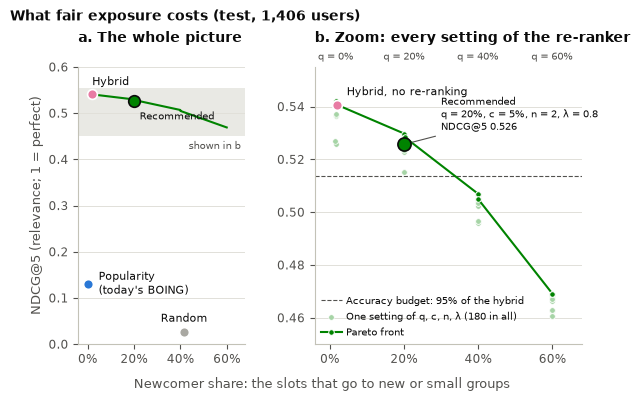

In [11]:
GREEN = br.colour('reranked')       # the proposed design's colour, as in every figure
LIGHT = '#a6d4a6'                   # a light tint of the same green: every other setting
dots = grid_test.drop_duplicates('lists_id')                     # settings with exactly the same lists share a dot
front = grid_test[grid_test.on_front].drop_duplicates('lists_id').sort_values('newcomer_share')
hyb, pop, rnd = grid_test.loc[HYB], baselines['popularity'], baselines['random']
budget_line = (1 - BUDGET) * hyb['ndcg@5']
ZOOM = (0.45, 0.555)                                             # the NDCG@5 range of panel b


def point(ax, row, method, size=50, edge='white'):
    ax.scatter(row['newcomer_share'], row['ndcg@5'], s=size, color=br.colour(method), edgecolor=edge, linewidth=1.2, zorder=5)


fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(br.WIDTH, 3.6), gridspec_kw={'width_ratios': [1, 1.6], 'wspace': 0.32})
for ax in (ax0, ax1):
    ax.yaxis.grid(True)
    ax.set_xlim(-0.04, 0.68)
    ax.set_xticks([0, 0.2, 0.4, 0.6])
    ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
fig.supxlabel('Newcomer share: the slots that go to new or small groups', fontsize=9, color=br.MUTED, y=-0.02)

# a. The whole picture
ax0.axhspan(*ZOOM, color=br.GRID, alpha=0.7, linewidth=0, zorder=0)
ax0.text(0.66, ZOOM[0] - 0.01, 'shown in b', ha='right', va='top', fontsize=7.5, color=br.MUTED)
ax0.plot(front.newcomer_share, front['ndcg@5'], '-', color=GREEN, linewidth=1.5, zorder=3)
for row, method, text, offset, ha in [(hyb, 'hybrid', 'Hybrid', (0, 9), 'left'),
                                      (pop, 'popularity', "Popularity\n(today's BOING)", (8, 0), 'left'),
                                      (rnd, 'random', 'Random', (0, 10), 'center')]:
    point(ax0, row, method)
    ax0.annotate(text, (row['newcomer_share'], row['ndcg@5']), xytext=offset, textcoords='offset points',
                 fontsize=8, color=br.INK, va='center', ha=ha)
point(ax0, rec_test, 'reranked', size=70, edge=br.INK)
ax0.annotate('Recommended', (rec_test['newcomer_share'], rec_test['ndcg@5']), xytext=(4, -13), textcoords='offset points',
             fontsize=7.5, color=br.INK)
ax0.set_ylim(0, 0.6)
ax0.set_ylabel('NDCG@5 (relevance; 1 = perfect)')
ax0.set_title('a. The whole picture', pad=18)

# b. Zoom: every setting
ax1.axhline(budget_line, color=br.MUTED, linestyle='--', linewidth=0.8, zorder=1,
            label=f'Accuracy budget: {1 - BUDGET:.0%} of the hybrid')
ax1.scatter(dots.newcomer_share, dots['ndcg@5'], s=16, color=LIGHT, edgecolor='white', linewidth=0.5, zorder=2,
            label=f'One setting of q, c, n, λ ({len(grid_test)} in all)')
ax1.plot(front.newcomer_share, front['ndcg@5'], '-o', color=GREEN, markersize=4, linewidth=1.5,
         markeredgecolor='white', markeredgewidth=0.7, zorder=3, label='Pareto front')
point(ax1, hyb, 'hybrid')
ax1.annotate('Hybrid, no re-ranking', (hyb['newcomer_share'], hyb['ndcg@5']), xytext=(7, 5), textcoords='offset points',
             fontsize=8, color=br.INK, va='bottom')
point(ax1, rec_test, 'reranked', size=90, edge=br.INK)
ax1.annotate(f'Recommended\nq = {Q:.0%}, c = {C_TEXT}, n = {N}, λ = {LAM:g}\nNDCG@5 {rec_test["ndcg@5"]:.3f}',
             (rec_test['newcomer_share'], rec_test['ndcg@5']), xytext=(0.30, 0.537), textcoords='data',
             fontsize=7.5, color=br.INK, va='center', arrowprops=dict(arrowstyle='-', color=br.MUTED, linewidth=0.8,
                                                                     shrinkA=2, shrinkB=6))
top = ax1.secondary_xaxis('top')                                 # name each column of dots by its quota
top.set_xticks([grid_test.loc[grid_test.q == q, 'newcomer_share'].mean() for q in QS])
top.set_xticklabels([f'q = {q:.0%}' for q in QS])
top.tick_params(length=0, labelsize=7.5, colors=br.MUTED)
top.spines['top'].set_visible(False)
ax1.set_ylim(*ZOOM)
ax1.set_title('b. Zoom: every setting of the re-ranker', pad=18)
ax1.legend(loc='lower left', fontsize=7.5, handletextpad=0.4, borderaxespad=0.2)
fig.suptitle(f'What fair exposure costs (test, {len(tested):,} users)', x=0.02, ha='left', y=1.04,
             fontsize=10, fontweight='bold', color=br.INK)
br.save_fig(fig, 'e2_tradeoff.png')
plt.show()

## 9 · Diversity: the topic cap n and the variety weight λ

At the recommended q and c: what lowering λ costs in accuracy (left) and gives in variety (right), for each topic cap n.
*Topics per list* counts the hidden topics (the scoring code only); *n = 5* means no topic cap.

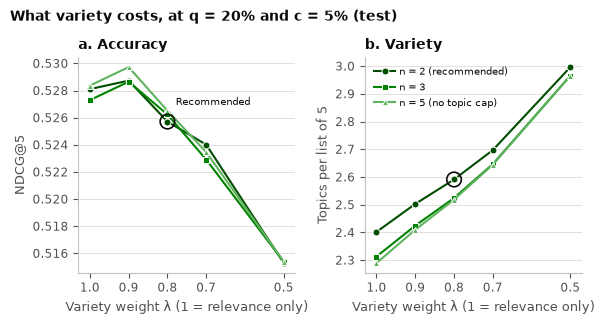

In [12]:
RAMP = {2: '#004d00', 3: GREEN, 5: '#5fb35f'}     # one green, darker = stricter topic cap (an ordered scale; checked)
SHAPE = {2: 'o', 3: 's', 5: '^'}                    # and a shape each, so the lines never rely on colour alone
fig, axes = plt.subplots(1, 2, figsize=(br.WIDTH, 2.8), gridspec_kw={'wspace': 0.32})
for ax, metric, ylabel, title in [(axes[0], 'ndcg@5', 'NDCG@5', 'a. Accuracy'),
                                  (axes[1], 'topics_per_list', 'Topics per list of 5', 'b. Variety')]:
    ax.yaxis.grid(True)
    for n in NS:
        line = with_c(grid_test, C).query('q == @Q and n == @n').sort_values('lam', ascending=False)
        ax.plot(line.lam, line[metric], '-', marker=SHAPE[n], color=RAMP[n], markersize=5, linewidth=1.5,
                markeredgecolor='white', markeredgewidth=0.7, zorder=3,
                label=f'n = {n}' + (' (no topic cap)' if n == K else ' (recommended)' if n == N else ''))
    ax.scatter([LAM], [rec_test[metric]], s=110, facecolor='none', edgecolor=br.INK, linewidth=1.2, zorder=4)
    ax.set_xlim(1.03, 0.47)                          # lambda from 1 (relevance only) to 0.5 (most variety)
    ax.set_xticks(LAMS)
    ax.set_xlabel('Variety weight λ (1 = relevance only)')
    ax.set_ylabel(ylabel)
    ax.set_title(title)
axes[0].annotate('Recommended', (LAM, rec_test['ndcg@5']), xytext=(6, 12), textcoords='offset points', fontsize=7.5,
                 color=br.INK)
axes[1].legend(loc='upper left', fontsize=7.5, handletextpad=0.4)
fig.suptitle(f'What variety costs, at q = {Q:.0%} and c = {C_TEXT} (test)', x=0.02, ha='left', y=1.05,
             fontsize=10, fontweight='bold', color=br.INK)
br.save_fig(fig, 'e2_diversity.png')
plt.show()

## 10 · The most telling settings, and one dial at a time

**The table for the report** (test). *Cost* is the NDCG@5 lost against the hybrid without re-ranking, on the same users, with its 95% range.

In [13]:
def nxt(values, v):
    return values[min(values.index(v) + 1, len(values) - 1)]

telling = [('Hybrid, no re-ranking', HYB),
           (f'Quota only (q = {Q:.0%})', setting(Q, None, 5, 1.0)),
           ('Recommended (E2)' + (' = design of notebook 06' if rec_key == E1 else ''), rec_key),
           ('Design of notebook 06 (E1)', E1),
           (f'More quota (q = {nxt(QS, Q):.0%})', setting(nxt(QS, Q), C, N, LAM)),
           (f'Most variety (λ = {LAMS[-1]:g})', setting(Q, C, N, LAMS[-1]))]
rows = {"Popularity (today's BOING)": {'q': np.nan, 'c': np.nan, 'n': np.nan, 'lam': np.nan, **pop[SHOW].to_dict()}}
seen = set()
for name_, key in telling:
    if key in seen:
        continue                                                       # the same setting twice: keep the first name
    seen.add(key)
    cost, low, high = paired_cost(pu_test, HYB, key)
    ndcg_low, ndcg_high = br.bootstrap_ci(pu_test[key])
    rows[name_] = {**grid_test.loc[key, ['q', 'c', 'n', 'lam']].to_dict(), **grid_test.loc[key, SHOW].to_dict(),
                   'ndcg@5 low': ndcg_low, 'ndcg@5 high': ndcg_high,
                   'cost': cost, 'cost low': low, 'cost high': high, 'relative cost': cost / hyb['ndcg@5']}
table = pd.DataFrame.from_dict(rows, orient='index')
table['c'] = table['c'].map(lambda c: 'none' if c is None or c != c else c)
table.loc["Popularity (today's BOING)", 'c'] = ''
br.save_table(table, 'e2_table.csv', decimals=4)
table[['q', 'c', 'n', 'lam', 'ndcg@5', 'cost', 'relative cost', 'hit_rate', 'newcomer_share', 'gini', 'coverage',
       'topics_per_list']].round(3)

,q,c,n,lam,ndcg@5,cost,relative cost,hit_rate,newcomer_share,gini,coverage,topics_per_list
Popularity (today's BOING),NaN,,NaN,NaN,0.131,NaN,NaN,0.220,0.000,0.953,10.0,3.228
"Hybrid, no re-ranking",0.0,none,5.0,1.0,0.541,0.000,0.000,0.687,0.020,0.640,106.0,2.555
Quota only (q = 20%),0.2,none,5.0,1.0,0.528,0.012,0.023,0.658,0.203,0.521,124.0,2.289
Recommended (E2),0.2,0.05,2.0,0.8,0.526,0.015,0.028,0.654,0.201,0.523,126.0,2.591
Design of notebook 06 (E1),0.2,0.1,2.0,1.0,0.528,0.013,0.023,0.656,0.203,0.511,125.0,2.402
More quota (q = 40%),0.4,0.05,2.0,0.8,0.504,0.037,0.068,0.604,0.400,0.468,126.0,2.464
Most variety (λ = 0.5),0.2,0.05,2.0,0.5,0.515,0.025,0.047,0.637,0.201,0.525,128.0,2.996


**One dial at a time**, around the recommended setting: each row changes one dial and keeps the other three. *Change* is the NDCG@5 gained (+) or lost (−)
against the recommended setting. The last rows are the global cap on the default list (personalisation off), where it binds.

In [14]:
def one_dial(grid, off, split):
    rows = []
    base = grid.loc[rec_key, 'ndcg@5']
    for dial, values in [('q', QS), ('n', NS), ('lam', LAMS), ('c', CS)]:
        for value in values:
            r = grid.loc[setting(**{**REC, dial: value})]
            rows.append({'split': split, 'dial': dial, 'value': 'none' if value is None else value, 'list': 'personalised',
                         'recommended': value == REC[dial], **r[SHOW].to_dict(), 'change': r['ndcg@5'] - base})
    off_base = off.loc[cap_name(C), 'ndcg@5']
    for c in CS:
        r = off.loc[cap_name(c)]
        rows.append({'split': split, 'dial': 'c', 'value': 'none' if c is None else c, 'list': 'personalisation off',
                     'recommended': c == C, **r[SHOW].to_dict(), 'change': r['ndcg@5'] - off_base})
    return pd.DataFrame(rows)


inp_off_test = reranker_inputs(tested, vis, stats, OFF)
same_lists.append(same_as_recommend(inp_off_test, inp_off_test['recs'], dials_of(OFF)))
off_test, pu_off_test = off_sweep(inp_off_test, key_test, dict(q=Q, n=N, lam=LAM))
off_e1 = sweep(inp_off_test, key_test, [tuple(dials_of(OFF).values())])[0].iloc[0]   # notebook 06's default list (for a check)
dials = pd.concat([one_dial(grid_val, off_val, 'validation'), one_dial(grid_test, off_test, 'test')], ignore_index=True)
dials.round(4).to_csv(br.RESULTS / 'e2_one_dial.csv', index=False)
dials[dials.split == 'test'].drop(columns='split').set_index(['dial', 'value'])[
    ['list', 'recommended', 'ndcg@5', 'change', 'hit_rate', 'newcomer_share', 'gini', 'coverage', 'topics_per_list']].round(3)

list  recommended  ndcg@5  change  hit_rate  \
dial value                                                               
q    0.0           personalised        False   0.540   0.014     0.688   
     0.2           personalised         True   0.526   0.000     0.654   
     0.4           personalised        False   0.504  -0.022     0.604   
     0.6           personalised        False   0.466  -0.059     0.532   
n    2             personalised         True   0.526   0.000     0.654   
     3             personalised        False   0.526   0.001     0.654   
     5             personalised        False   0.527   0.001     0.655   
lam  1.0           personalised        False   0.528   0.002     0.656   
     0.9           personalised        False   0.529   0.003     0.657   
     0.8           personalised         True   0.526   0.000     0.654   
     0.7           personalised        False   0.524  -0.002     0.653   
     0.5           personalised        False   0.515  -0.010     0.637   
c    0.05          personalised         True   0.526   0.000     0.654   
     0.1           personalised        False   0.526   0.000     0.654   
     none          personalised        False   0.526   0.000     0.654   
     0.05   personalisation off         True   0.065   0.000     0.102   
     0.1    personalisation off        False   0.059  -0.006     0.091   
     none   personalisation off        False   0.025  -0.040     0.043   

            newcomer_share   gini  coverage  topics_per_list  
dial value                                                    
q    0.0             0.016  0.656       108            2.853  
     0.2             0.201  0.523       126            2.591  
     0.4             0.400  0.468       126            2.464  
     0.6             0.600  0.496       125            2.522  
n    2               0.201  0.523       126            2.591  
     3               0.201  0.521       126            2.524  
     5               0.201  0.521       127            2.518  
lam  1.0             0.203  0.511       125            2.402  
     0.9             0.202  0.520       126            2.503  
     0.8             0.201  0.523       126            2.591  
     0.7             0.201  0.526       127            2.697  
     0.5             0.201  0.525       128            2.996  
c    0.05            0.201  0.523       126            2.591  
     0.1             0.201  0.523       126            2.591  
     none            0.201  0.523       126            2.591  
     0.05            0.491  0.844        23            3.807  
     0.1             0.591  0.921        14            4.170  
     none            0.799  0.961         8            4.159

## 11 · The recommendation, dial by dial

For each dial: what it **costs** in accuracy (the NDCG@5 lost on the test, on the same users, against the recommended setting with only that dial
switched off, with its 95% range), what it **gives** in exposure or variety, and the **value** it serves. The global cap c is measured on the default
list (personalisation off), the only place where it binds. The paragraph printed below is written from these numbers, and saved with them.

In [15]:
VALUES = {'q': 'equity and inclusion (R4): a new or small group cannot gain members if nobody sees it',
          'c': 'equity (R4): no group takes everyone\'s attention',
          'n': 'diversity and autonomy (R5): a list that is not all one subject leaves the member a real choice',
          'lam': 'diversity (R5): groups unlike each other in a list'}
OFF_VALUES = {'q': 0.0, 'n': K, 'lam': 1.0, 'c': None}   # each dial switched off


def dial_effect(dial):
    # The recommended setting against the same setting with one dial switched off (test, same users)
    if dial == 'c':                                    # on the default list, where the cap binds
        cost, low, high = paired_cost(pu_off_test, 'no cap', cap_name(C))
        before, after = off_test.loc['no cap'], off_test.loc[cap_name(C)]
        where = 'personalisation off'
    else:
        ref = setting(**{**REC, dial: OFF_VALUES[dial]})
        cost, low, high = paired_cost(pu_test, ref, rec_key)
        before, after = grid_test.loc[ref], grid_test.loc[rec_key]
        where = 'personalised'
    gains = ['newcomer_share', 'gini', 'coverage', 'largest_share', 'topics_per_list'] + (['diversity'] if dial != 'c' else [])
    return {'value': REC[dial], 'switched off': OFF_VALUES[dial], 'measured on': where, 'value served': VALUES[dial],
            'ndcg@5 off': float(before['ndcg@5']), 'ndcg@5 on': float(after['ndcg@5']),
            'cost': cost, 'cost low': low, 'cost high': high, 'relative cost': cost / float(before['ndcg@5']),
            **{f'{k} off': float(before[k]) for k in gains}, **{f'{k} on': float(after[k]) for k in gains}}


effects = {d: dial_effect(d) for d in ['q', 'c', 'n', 'lam']}
def rng_(e):
    # A cost in words; a negative cost is a gain
    if e['cost'] < 0:
        return f'nothing: NDCG@5 even rises by {-e["cost"]:.3f} (95% range {-e["cost high"]:.3f} to {-e["cost low"]:.3f})'
    return f'{e["cost"]:.3f} NDCG@5 (95% range {e["cost low"]:.3f} to {e["cost high"]:.3f}; {e["relative cost"]:.1%})'



e = effects
paragraph = [
    f'Quota q = {Q:.0%} ({math.ceil(Q * K - 1e-9)} of the 5 slots). It costs {rng_(e["q"])} and raises the share of slots for new or '
    f'small groups from {e["q"]["newcomer_share off"]:.0%} to {e["q"]["newcomer_share on"]:.0%}; {e["q"]["coverage on"]:.0f} groups are '
    f'shown instead of {e["q"]["coverage off"]:.0f}, and the Gini of exposure falls from {e["q"]["gini off"]:.2f} to {e["q"]["gini on"]:.2f}. '
    f'It serves {VALUES["q"]}.',
    f'Global cap c = {C_TEXT}. On personalised lists it changes nothing: no group reaches {min(c for c in CS if c is not None):.0%} of the '
    f'slots there (at most {grid_test.largest_share.max():.1%} in any setting). On the default list, where every member sees nearly the same '
    f'groups, it costs {rng_(e["c"])} and shows {e["c"]["coverage on"]:.0f} groups instead of {e["c"]["coverage off"]:.0f}; the most-shown '
    f'group falls from {e["c"]["largest_share off"]:.0%} to {e["c"]["largest_share on"]:.0%} of the slots. It serves {VALUES["c"]}.',
    f'Topic cap n = {N}. It costs {rng_(e["n"])} and raises the hidden topics in a list of 5 from {e["n"]["topics_per_list off"]:.2f} '
    f'to {e["n"]["topics_per_list on"]:.2f}. It serves {VALUES["n"]}.' if N != K else
    f'Topic cap n = {N} (no cap): a stricter cap costs more than the tolerance on the practice quiz. It would serve {VALUES["n"]}.',
    f'Variety weight λ = {LAM:g}. It costs {rng_(e["lam"])} and raises the topics in a list from {e["lam"]["topics_per_list off"]:.2f} '
    f'to {e["lam"]["topics_per_list on"]:.2f} (description diversity {e["lam"]["diversity off"]:.3f} to {e["lam"]["diversity on"]:.3f}). '
    f'It serves {VALUES["lam"]}.' if LAM != 1.0 else
    f'Variety weight λ = 1 (relevance only): lowering it costs more than the tolerance on the practice quiz, and the topic cap already keeps '
    f'lists varied. It would serve {VALUES["lam"]}.',
]
together = paired_cost(pu_test, HYB, rec_key)
paragraph.append(f'Together, the four dials cost {together[0]:.3f} NDCG@5 against the hybrid without re-ranking '
                 f'({together[0] / hyb["ndcg@5"]:.1%} of its {hyb["ndcg@5"]:.3f}; 95% range {together[1]:.3f} to {together[2]:.3f}), '
                 f'within the {BUDGET:.0%} budget chosen on the practice quiz, and members still find a hidden group in '
                 f'{rec_test["hit_rate"]:.0%} of lists (today\'s BOING: {pop["hit_rate"]:.0%}).')
for p in paragraph:
    print('-', p, '\n')
pd.DataFrame(effects).T[['value', 'measured on', 'ndcg@5 off', 'ndcg@5 on', 'cost', 'cost low', 'cost high', 'newcomer_share off',
                         'newcomer_share on', 'coverage off', 'coverage on', 'topics_per_list off', 'topics_per_list on']]

- Quota q = 20% (1 of the 5 slots). It costs 0.014 NDCG@5 (95% range 0.010 to 0.019; 2.7%) and raises the share of slots for new or small groups from 2% to 20%; 126 groups are shown instead of 108, and the Gini of exposure falls from 0.66 to 0.52. It serves equity and inclusion (R4): a new or small group cannot gain members if nobody sees it. 

- Global cap c = 5%. On personalised lists it changes nothing: no group reaches 5% of the slots there (at most 4.7% in any setting). On the default list, where every member sees nearly the same groups, it costs nothing: NDCG@5 even rises by 0.040 (95% range 0.028 to 0.051) and shows 23 groups instead of 8; the most-shown group falls from 20% to 5% of the slots. It serves equity (R4): no group takes everyone's attention. 

- Topic cap n = 2. It costs 0.001 NDCG@5 (95% range -0.001 to 0.003; 0.2%) and raises the hidden topics in a list of 5 from 2.52 to 2.59. It serves diversity and autonomy (R5): a list that is not all one subject leaves the memb

,value,measured on,ndcg@5 off,ndcg@5 on,cost,cost low,cost high,newcomer_share off,newcomer_share on,coverage off,coverage on,topics_per_list off,topics_per_list on
q,0.2,personalised,0.54012,0.525714,0.014406,0.010429,0.018765,0.016216,0.200853,108.0,126.0,2.852774,2.591038
c,0.05,personalisation off,0.025264,0.064978,-0.039714,-0.050872,-0.028174,0.799147,0.490754,8.0,23.0,4.158606,3.807255
n,2,personalised,0.526514,0.525714,0.000799,-0.001306,0.002993,0.200853,0.200853,127.0,126.0,2.518492,2.591038
lam,0.8,personalised,0.528105,0.525714,0.002391,-0.001962,0.007005,0.202703,0.200853,125.0,126.0,2.401849,2.591038


## 12 · Saving the results

In [16]:
def save_grid():
    out = []
    for split, g in [('validation', grid_val), ('test', grid_test)]:
        out.append(g.drop(columns=['lists_id', 'most_of_one_topic', 'fewest_newcomers', 'valid_lists'])
                   .reset_index().assign(split=split))
    grid = pd.concat(out, ignore_index=True)
    grid['c'] = grid['c'].map(lambda c: 'none' if c is None or c != c else c)
    grid = grid[['split', 'setting'] + [col for col in grid.columns if col not in ('split', 'setting')]]
    grid.round(4).to_csv(br.RESULTS / 'e2_grid.csv', index=False)
    return grid


saved_grid = save_grid()
off_both = pd.concat([off_val.assign(split='validation'), off_test.assign(split='test')])
off_both['c'] = off_both['c'].map(lambda c: 'none' if c != c else c)
off_both.round(4).to_csv(br.RESULTS / 'e2_off_cap.csv')

cost, low, high = paired_cost(pu_test, HYB, rec_key)
cost_e1, low_e1, high_e1 = paired_cost(pu_test, E1, rec_key)
ndcg_low, ndcg_high = br.bootstrap_ci(pu_test[rec_key])
r4 = lambda v: round(float(v), 4)
recommendation = {
    'experiment': 'E2: what fair exposure (R4) and diversity (R5) cost',
    'recommended': {'q': Q, 'c': C, 'n': N, 'lam': LAM},
    'notebook_06_defaults': {'q': cfg.q, 'c': cfg.c, 'n': cfg.n, 'lam': cfg.lam},
    'differs_from_defaults': [d for d in REC if REC[d] != getattr(cfg, d)],
    'rule': (f'Chosen on the practice quiz only. Budget: keep at least {1 - BUDGET:.0%} of the hybrid\'s NDCG@5 (no re-ranking). '
             'q: the largest that fits the budget (n = 5, lambda = 1, no cap). n, then lambda: the strictest topic cap, then the lowest '
             f'lambda (lowered one step at a time), whose paired NDCG@5 cost against the same setting without that dial is at most '
             f'{TOL:.0%} of the hybrid\'s (the tolerance) and whose whole setting still fits the budget. '
             'c: the strictest cap whose paired cost against no cap is at most the tolerance, both on the personalised lists '
             '(where it never binds) and on the default list (personalisation off).'),
    'budget': BUDGET,
    'tolerance': TOL,
    'validation': {'users': int(rec_val['users']), 'hybrid ndcg@5': r4(steps['hybrid']), 'ndcg@5': r4(rec_val['ndcg@5']),
                   'share of the hybrid': r4(rec_val['ndcg@5'] / steps['hybrid']), 'newcomer_share': r4(rec_val['newcomer_share']),
                   'topics_per_list': r4(rec_val['topics_per_list'])},
    'test': {'users': int(rec_test['users']), **{k: r4(rec_test[k]) for k in ['hit_rate', 'precision@5', 'recall@5', 'ndcg@5']},
             'ndcg@5 low': r4(ndcg_low), 'ndcg@5 high': r4(ndcg_high),
             **{k: r4(rec_test[k]) for k in ['newcomer_share', 'gini', 'largest_share', 'topics_per_list', 'diversity',
                                             'clusters_per_list', 'quota_slots']},
             'coverage': int(rec_test['coverage']),
             'hybrid ndcg@5': r4(hyb['ndcg@5']), 'hybrid newcomer_share': r4(hyb['newcomer_share']),
             'cost vs hybrid': r4(cost), 'cost vs hybrid low': r4(low), 'cost vs hybrid high': r4(high),
             'relative cost vs hybrid': r4(cost / hyb['ndcg@5']),
             'cost vs notebook 06 design': r4(cost_e1), 'cost vs notebook 06 design low': r4(low_e1),
             'cost vs notebook 06 design high': r4(high_e1),
             'popularity ndcg@5': r4(pop['ndcg@5']), 'popularity newcomer_share': r4(pop['newcomer_share']),
             'on the pareto front': bool(rec_test['on_front'])},
    'steps on the practice quiz': {
        'q': {f'{q:.0%}': {'ndcg@5': r4(r['ndcg@5']), 'cost': r4(r['cost (share of the hybrid)']), 'fits': bool(r['fits the budget'])}
              for q, r in steps['q'].iterrows()},
        **{dial: {f'{v:g}': {'ndcg@5': r4(r['ndcg@5']), 'cost': r4(r['cost']), 'cost (share of the hybrid)':
                              r4(r['cost (share of the hybrid)']), 'low': r4(r['cost low']), 'high': r4(r['cost high']),
                              'within tolerance': bool(r['within tolerance']), 'fits the budget': bool(r['fits the budget']),
                              'topics_per_list': r4(r['topics_per_list'])} for v, r in steps[dial].iterrows()}
           for dial in ['n', 'lam']},
        'c': {cap: {k: (bool(v) if k == 'ok' else int(v) if k.startswith('coverage') else r4(v)) for k, v in r.items()}
              for cap, r in steps['c'].iterrows()}},
    'other budgets and tolerances (practice quiz)': [
        {'budget': r.budget, 'tolerance': r.tolerance, 'q': float(r.q), 'n': int(r.n), 'lam': float(r.lam),
         'ndcg@5': r4(r['ndcg@5']), 'share of the hybrid': r4(r['share of the hybrid']), 'newcomer_share': r4(r['newcomer_share']),
         'topics_per_list': r4(r['topics_per_list'])} for _, r in budgets.iterrows()],
    'c changes personalised lists (combinations of 60)': {'validation': c_changes(grid_val), 'test': c_changes(grid_test)},
    'largest share of one group, any personalised setting': {'validation': r4(grid_val.largest_share.max()),
                                                             'test': r4(grid_test.largest_share.max())},
    'spearman ndcg@5 validation vs test': r4(agree),
    'settings on the test pareto front': int(grid_test.on_front.sum()),
    'dials (test; each against the recommended setting with only that dial switched off)': {
        d: {k: (r4(v) if isinstance(v, float) and v == v else v) for k, v in eff.items()} for d, eff in effects.items()},
    'plain_language': paragraph,
}
(br.RESULTS / 'e2_recommendation.json').write_text(json.dumps(recommendation, indent=2, ensure_ascii=False))
print(json.dumps(recommendation['test'], indent=1))

{
 "users": 1406,
 "hit_rate": 0.6536,
 "precision@5": 0.1374,
 "recall@5": 0.6319,
 "ndcg@5": 0.5257,
 "ndcg@5 low": 0.5015,
 "ndcg@5 high": 0.5489,
 "newcomer_share": 0.2009,
 "gini": 0.5229,
 "largest_share": 0.032,
 "topics_per_list": 2.591,
 "diversity": 0.9495,
 "clusters_per_list": 3.9602,
 "quota_slots": 0.1846,
 "coverage": 126,
 "hybrid ndcg@5": 0.5407,
 "hybrid newcomer_share": 0.0201,
 "cost vs hybrid": 0.015,
 "cost vs hybrid low": 0.0096,
 "cost vs hybrid high": 0.0203,
 "relative cost vs hybrid": 0.0277,
 "cost vs notebook 06 design": 0.0024,
 "cost vs notebook 06 design low": -0.002,
 "cost vs notebook 06 design high": 0.007,
 "popularity ndcg@5": 0.1311,
 "popularity newcomer_share": 0.0,
 "on the pareto front": false
}


## 13 · Checks

In [17]:
picks_rec, _, _ = rerank_with(inp_test, **REC)
picks_again, _, _ = rerank_with(inp_test, **REC)
need = {q: int(np.ceil(q * K - 1e-9)) for q in QS}
e1_row = lambda m: e1.loc[br.label(m)]
same_metrics = lambda row, e1r: all(abs(row[k] - e1r[k]) < 5e-4 for k in ['hit_rate', 'ndcg@5', 'newcomer_share', 'gini', 'coverage'])

checks = {
    're-running only the re-ranker gives exactly recommend()\'s lists and quota slots (personalised: 2 settings on the quiz, '
    '1 on the test; default list: 1 on each)':
        all(same_lists) and len(same_lists) == 5,
    'the fast numbers equal br.evaluate(), br.list_diversity() and br.relevance_per_user() (3 settings on the quiz, the recommended one on the test)':
        all(same_numbers) and len(same_numbers) == 2,
    'every user gets 5 different groups they may be shown, in every setting (both splits)':
        all(g.valid_lists.all() for g in (grid_val, grid_test))
        and len(grid_val) == len(grid_test) == len(QS) * len(CS) * len(NS) * len(LAMS),
    'the rule compared settings without a cap: fair, because c changes no personalised list on the practice quiz':
        c_changes(grid_val) == 0,
    'quota (R4): in every setting, every list has at least ceil(q x 5) new or small groups (both splits)':
        all((g.fewest_newcomers >= g.q.map(need)).all() for g in (grid_val, grid_test)),
    'topic cap (R5): in every setting, no list has more than n groups of one public topic (both splits)':
        all((g.most_of_one_topic <= g.n).all() for g in (grid_val, grid_test)),
    'global cap (R4): no group gets more than c of all slots, in every setting with a cap (both splits)':
        all((g.largest_share[g.c.notna()] <= g.c[g.c.notna()].astype(float) + 1e-12).all() for g in (grid_val, grid_test))
        and all((o.largest_share[o.c.notna()] <= o.c[o.c.notna()].astype(float) + 1e-12).all() for o in (off_val, off_test)),
    'no rule had to be relaxed in any setting (both splits, and the default list)':
        all(g.times_relaxed.sum() == 0 for g in (grid_val, grid_test)) and all(o.times_relaxed.sum() == 0 for o in (off_val, off_test)),
    'the test numbers of the hybrid, the design of notebook 06, its default list and popularity equal the E1 table':
        same_metrics(hyb, e1_row('hybrid')) and same_metrics(grid_test.loc[E1], e1_row('reranked'))
        and same_metrics(off_e1, e1_row('off')) and same_metrics(pop, e1_row('popularity')),
    'the choice used the practice quiz only, and the recommended setting keeps the budget there':
        choose(grid_val, pu_val)[0] == (Q, N, LAM) and rec_val['ndcg@5'] >= (1 - BUDGET) * steps['hybrid'],
    'on the test, the recommended setting gives new or small groups at least q of the slots':
        rec_test['newcomer_share'] >= Q - 1e-12,
    'same seed, same results: the re-ranker run again gives the same lists': np.array_equal(picks_rec, picks_again),
    'the saved grid has every setting on both splits, and the recommendation file names the recommended setting':
        len(saved_grid) == 2 * len(grid_test) and saved_grid.recommended.sum() == 2
        and json.loads((br.RESULTS / 'e2_recommendation.json').read_text())['recommended'] == REC,
    'a recommender never gets a hidden column or a test membership':
        not {'interests', 'is_fake'} & set(vis.users.columns) and 'topic' not in vis.groups.columns
        and not set(zip(vis.train.user_id, vis.train.group_id)) & set(zip(ans.test.user_id, ans.test.group_id)),
}
for check, ok_ in checks.items():
    print('✓' if ok_ else '✗', check)
assert all(checks.values()), 'Some checks failed (see ✗ above)'

✓ re-running only the re-ranker gives exactly recommend()'s lists and quota slots (personalised: 2 settings on the quiz, 1 on the test; default list: 1 on each)
✓ the fast numbers equal br.evaluate(), br.list_diversity() and br.relevance_per_user() (3 settings on the quiz, the recommended one on the test)
✓ every user gets 5 different groups they may be shown, in every setting (both splits)
✓ the rule compared settings without a cap: fair, because c changes no personalised list on the practice quiz
✓ quota (R4): in every setting, every list has at least ceil(q x 5) new or small groups (both splits)
✓ topic cap (R5): in every setting, no list has more than n groups of one public topic (both splits)
✓ global cap (R4): no group gets more than c of all slots, in every setting with a cap (both splits)
✓ no rule had to be relaxed in any setting (both splits, and the default list)
✓ the test numbers of the hybrid, the design of notebook 06, its default list and popularity equal the E1 table
✓

## What we learned

- **Fair exposure is cheap for one slot, then gets dearer.** On the test (1,406 users) the hybrid without re-ranking gives new or small groups 2% of the slots,
  with NDCG@5 = 0.541. With the other dials as recommended, each extra quota slot costs more than the last: one slot in five (q = 20%) costs 0.014 NDCG@5,
  a second (q = 40%) 0.022 more, a third (q = 60%) 0.038 more. The newcomer share follows q almost exactly (20%, 40%, 60%).
- **The recommended dials**, chosen on the practice quiz only with a rule stated in section 4 (members keep 95% of the hybrid's NDCG@5; fair exposure gets
  the budget first; each variety dial may then cost at most 1%). What each one costs and gives on the test, against the same setting without it:

| Dial | Setting | Costs (NDCG@5) | Gives | Value it serves |
|---|---|---|---|---|
| q, quota | 20% (1 slot of 5) | 0.014 (2.7%; 95% range 0.010 to 0.019) | new or small groups get 20% of the slots, not 2%; 126 groups shown, not 108; Gini 0.66 → 0.52 | equity, inclusion (R4) |
| c, global cap | 5% | nothing: it never changes a personalised list (no group reaches 5% of the slots there) | on the default list: 23 groups shown, not 8; the most-shown group falls from 20% to 5% of the slots; NDCG@5 even rises (0.025 → 0.065) | equity (R4) |
| n, topic cap | 2 | 0.001 (within noise) | 2.52 → 2.59 topics per list | diversity, autonomy (R5) |
| λ, variety | 0.8 | 0.002 (within noise) | 2.40 → 2.59 topics per list | diversity (R5) |

- **Together they cost 0.015 NDCG@5** against the hybrid (2.8%; 95% range 0.010 to 0.020): NDCG@5 = 0.526 and a hit rate of 65% (today's BOING: 0.131 and 22%),
  with 20% of the slots for new or small groups, 126 of the 129 Discover groups shown and no group above 3.2% of the slots. No rule ever had to be relaxed.
- **Two changes to notebook 06's design: c = 5% (not 10%) and λ = 0.8 (not 1).** The tighter cap only acts on the default list, where it shows 23 groups
  instead of 14; its accuracy there is within noise of the 10% cap (better on the test, worse on the practice quiz). λ = 0.8 adds 0.19 topics per list for
  0.002 NDCG@5, also within noise.
- **Other value judgements would choose differently** (practice quiz): a 10% accuracy budget gives q = 40% (two slots), 15% or more gives q = 60%;
  a 2.5% budget or a 0.5% tolerance keeps q = 20% with a looser topic cap (n = 3); a 2% tolerance lowers λ to 0.7.
- **The trade-off curve** (`figures/e2_tradeoff.png`): the recommended setting sits 0.004 NDCG@5 below the two-way Pareto front (accuracy, newcomer share),
  because it spends that on variety (2.59 topics per list instead of 2.41); with variety as a third axis it is on the front.
- **The results hold up:** the practice quiz and the test rank the 180 settings almost the same way (rank correlation 0.97), and every check passes.
- **Files:** `results/e2_grid.csv` (every setting, both splits), `results/e2_recommendation.json` (the dials, the rule, the numbers above and the plain-language
  paragraph of section 11), `results/e2_table.csv` (the report's table), `results/e2_one_dial.csv`, `results/e2_off_cap.csv`, `figures/e2_tradeoff.png`,
  `figures/e2_diversity.png`.

**For the next steps:** the recommended design is `br.Config(c=0.05, lam=0.8)`. This notebook does not change the defaults in `boingrec.py`, so the E1 numbers
of notebook 06 stay as they are.